# 00d — Beatriz: DEC e FEC por Alimentador (Dados Brutos)
Objetivo: calcular DEC e FEC por ano e total, por alimentador, com UCs contadas como linhas do cadastro e como id_uc distintos.

In [1]:
import sys
from pathlib import Path

# Resolução de caminho compatível com script .py e notebook .ipynb (sem __file__ em notebooks)
_starts = [Path.cwd()]
if "__file__" in globals():
    _starts.append(Path(__file__).resolve().parent)

def _find_project_root(starts):
    checked = []
    for item in starts:
        current = item.resolve()
        if current.is_file():
            current = current.parent
        for candidate in (current, *current.parents):
            if candidate in checked:
                continue
            checked.append(candidate)
            if (candidate / "data").is_dir() and (candidate / "analisys").is_dir():
                return candidate
    locations = ", ".join(str(s.resolve()) for s in starts)
    raise FileNotFoundError(
        f"Raiz do projeto não encontrada. Esperado 'data/' e 'analisys/' a partir de: {locations}"
    )

PROJECT_ROOT = _find_project_root(_starts)
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import json
import matplotlib
# Backend inline para exibir gráficos no notebook
import matplotlib_inline.backend_inline
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

# Configuração para saída de alta qualidade no notebook
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

# Carregamento dos dados brutos (funções inline, sem _helpers)

In [2]:
_REQUIRED_DATA_FILES = (
    "unidades_consumidoras.csv",
    "medidores.csv",
    "faturas.csv",
    "geracao_distribuida.csv",
    "ocorrencias_rede.csv",
    "atendimentos.json",
    "inspecoes.xlsx",
)

def _read_csv(path: Path, **kwargs) -> pd.DataFrame:
    sample = path.read_text(encoding="utf-8", errors="replace").splitlines()[:1]
    if not sample:
        raise ValueError(f"Arquivo CSV vazio: {path}")
    separator = ";" if sample[0].count(";") > sample[0].count(",") else ","
    options = {"sep": separator, **kwargs}
    try:
        return pd.read_csv(path, **options)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", **options)

def _read_file(path: Path, **kwargs) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return _read_csv(path, **kwargs)
    if suffix == ".json":
        return pd.read_json(path, **kwargs)
    if suffix == ".xlsx":
        return pd.read_excel(path, **kwargs)
    raise ValueError(f"Formato não suportado: {path}")

def resolve_data_file(name: str, root: Path) -> Path:
    data_dir = root / "data"
    direct = data_dir / name
    if direct.is_file():
        return direct
    matches = sorted(p for p in data_dir.rglob(Path(name).name) if p.is_file())
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(f"Arquivo obrigatório '{name}' não encontrado em {data_dir} nem subdiretórios.")
    raise FileNotFoundError(f"Arquivo '{name}' encontrado em múltiplos locais: {', '.join(str(p) for p in matches)}")

def resolve_readings_files(root: Path) -> list[Path]:
    data_dir = root / "data"
    candidates = sorted(p for p in data_dir.rglob("*.csv") if p.is_file() and "leitura" in p.stem.lower())
    if not candidates:
        raise FileNotFoundError(f"Nenhum CSV de leituras encontrado em {data_dir} ou subdiretórios.")
    return candidates

def load_all_raw_data(root: Path) -> dict[str, pd.DataFrame]:
    files = {name.removesuffix(Path(name).suffix): resolve_data_file(name, root) for name in _REQUIRED_DATA_FILES}
    files["leituras"] = resolve_readings_files(root)
    return {
        "uc": _read_file(files["unidades_consumidoras"]),
        "faturas": _read_file(files["faturas"]),
        "leituras": pd.concat([_read_file(p) for p in files["leituras"]], ignore_index=True, sort=False),
        "medidores": _read_file(files["medidores"]),
        "gd": _read_file(files["geracao_distribuida"]),
        "ocorrencias": _read_file(files["ocorrencias_rede"]),
        "atendimentos": _read_file(files["atendimentos"]),
        "inspecoes": _read_file(files["inspecoes"]),
    }

def to_numeric_safe(series: pd.Series, decimal_comma: bool = False) -> tuple[pd.Series, int]:
    values = series.astype("string").str.strip()
    if decimal_comma:
        values = values.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    converted = pd.to_numeric(values, errors="coerce")
    failures = int((values.notna() & values.ne("") & converted.isna()).sum())
    return converted, failures

def safe_divide(numerator: float, denominator: float):
    if denominator is None or pd.isna(denominator) or denominator == 0:
        return None
    return float(numerator / denominator)

def get_resultados_dir(subdir: str, root: Path) -> Path:
    directory = root / "analisys" / "resultados" / subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

def get_graficos_dir(subdir: str | None, root: Path) -> Path:
    directory = root / "analisys" / "graficos"
    if subdir:
        directory /= subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

# Carrega dados
dfs = load_all_raw_data(PROJECT_ROOT)

# Diretórios de saída
PASTA_RESULTADOS = get_resultados_dir("analise_negocio/dados_brutos", PROJECT_ROOT)
PASTA_GRAFICOS = get_graficos_dir("analise_negocio", PROJECT_ROOT)

def exibir_grafico(fig, nome: str):
    output = PASTA_GRAFICOS / f"{nome}.png"
    fig.savefig(output, dpi=150, bbox_inches="tight")
    print(f"Gráfico gerado: {output}")
    plt.show(fig)  # Exibe no notebook
    plt.close(fig)  # Libera memória

C:\Users\julio\AppData\Local\Temp\ipykernel_13872\2939567294.py:18: DtypeWarning: Columns (4,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)
C:\Users\julio\AppData\Local\Temp\ipykernel_13872\2939567294.py:18: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)


In [3]:
uc = dfs["uc"]
oco = dfs["ocorrencias"]

# UCs por alimentador - duas contagens: linhas do cadastro e id_uc distintos
ucs_por_alim_linhas = uc.groupby("alimentador").size().rename("n_ucs_linhas")
ucs_por_alim_distintos = uc.groupby("alimentador")["id_uc"].nunique().rename("n_ucs_distintos")
print(f"Alimentadores com UCs (linhas): {len(ucs_por_alim_linhas)}")
print(f"Alimentadores com UCs (distintos): {len(ucs_por_alim_distintos)}")

# Ocorrências: converter duracao_min e data_abertura
# Detectar formato de data_abertura (não fixar)
oco["duracao_min_num"] = pd.to_numeric(oco["duracao_min"].astype(str).str.replace(",", "."), errors="coerce")
falhas_dur = int(oco["duracao_min_num"].isna().sum())

# Tentar converter data_abertura com múltiplos formatos
def parse_data_abertura(series):
    """Tenta múltiplos formatos de data."""
    # Formatos comuns
    for fmt in ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%d/%m/%Y %H:%M:%S", "%d/%m/%Y"]:
        try:
            parsed = pd.to_datetime(series, format=fmt, errors="raise")
            return parsed
        except:
            continue
    # Fallback: infer
    return pd.to_datetime(series, errors="coerce")

oco["data_abertura_dt"] = parse_data_abertura(oco["data_abertura"])
falhas_data = int(oco["data_abertura_dt"].isna().sum())

print(f"Falhas conversão duracao_min: {falhas_dur}")
print(f"Falhas conversão data_abertura: {falhas_data}")

# Adicionar ano
oco["ano"] = oco["data_abertura_dt"].dt.year

Alimentadores com UCs (linhas): 123
Alimentadores com UCs (distintos): 123
Falhas conversão duracao_min: 16200
Falhas conversão data_abertura: 0


In [4]:
# Função para calcular DEC/FEC para um DataFrame de ocorrências e contagem de UCs
def calcula_dec_fec(oco_df, ucs_linhas, ucs_distintos, sufixo=""):
    """Calcula DEC e FEC por alimentador."""
    # Agregar ocorrências por alimentador
    oco_por_alim = oco_df.groupby("alimentador").agg(
        n_ocorrencias=("id_ocorrencia", "count"),
        soma_duracao_min=("duracao_min_num", "sum")
    ).reset_index()

    # Juntar com UCs (linhas)
    df_linhas = oco_por_alim.merge(ucs_linhas.rename("n_ucs"), left_on="alimentador", right_index=True, how="left")
    df_linhas["n_ucs"] = df_linhas["n_ucs"].fillna(0).astype(int)

    # Juntar com UCs (distintos)
    df_distintos = oco_por_alim.merge(ucs_distintos.rename("n_ucs"), left_on="alimentador", right_index=True, how="left")
    df_distintos["n_ucs"] = df_distintos["n_ucs"].fillna(0).astype(int)

    # FEC = n_ocorrencias / UCs
    df_linhas["FEC"] = df_linhas.apply(lambda r: r["n_ocorrencias"] / r["n_ucs"] if r["n_ucs"] > 0 else np.nan, axis=1)
    df_distintos["FEC"] = df_distintos.apply(lambda r: r["n_ocorrencias"] / r["n_ucs"] if r["n_ucs"] > 0 else np.nan, axis=1)

    # DEC = (soma_duracao_min / 60) / UCs
    df_linhas["DEC_horas"] = df_linhas.apply(lambda r: (r["soma_duracao_min"] / 60) / r["n_ucs"] if r["n_ucs"] > 0 else np.nan, axis=1)
    df_distintos["DEC_horas"] = df_distintos.apply(lambda r: (r["soma_duracao_min"] / 60) / r["n_ucs"] if r["n_ucs"] > 0 else np.nan, axis=1)

    return df_linhas, df_distintos

In [5]:
# Cálculo total (todo o período)
df_linhas_total, df_distintos_total = calcula_dec_fec(oco, ucs_por_alim_linhas, ucs_por_alim_distintos, "_total")

print("Top 10 por DEC (linhas do cadastro):")
top10_dec_linhas = df_linhas_total.nlargest(10, "DEC_horas")[["alimentador", "DEC_horas", "FEC", "n_ucs"]]
print(top10_dec_linhas.to_string(index=False))

print("\nTop 10 por DEC (UCs distintas):")
top10_dec_dist = df_distintos_total.nlargest(10, "DEC_horas")[["alimentador", "DEC_horas", "FEC", "n_ucs"]]
print(top10_dec_dist.to_string(index=False))

print("\nTop 10 por FEC (linhas do cadastro):")
top10_fec_linhas = df_linhas_total.nlargest(10, "FEC")[["alimentador", "FEC", "DEC_horas", "n_ucs"]]
print(top10_fec_linhas.to_string(index=False))

Top 10 por DEC (linhas do cadastro):
alimentador  DEC_horas       FEC  n_ucs
ALM-JAB-016 104.200758 62.454545     22
ALM-JAB-019  67.561458 43.281250     32
ALM-JAB-015  63.539524 39.685714     35
ALM-REC-039  63.330303 40.878788     33
ALM-SAO-001  62.977273 41.212121     33
ALM-JAB-008  53.404825 35.947368     38
ALM-PAU-007  49.570922 29.936170     47
ALM-REC-009  32.042172 20.772727     66
ALM-REC-045  26.670996 17.467532     77
ALM-SAO-003  25.998659 16.586207     87

Top 10 por DEC (UCs distintas):
alimentador  DEC_horas       FEC  n_ucs
ALM-JAB-016 114.620833 68.700000     20
ALM-JAB-019  67.561458 43.281250     32
ALM-JAB-015  65.408333 40.852941     34
ALM-REC-039  65.309375 42.156250     32
ALM-SAO-001  64.945312 42.500000     32
ALM-JAB-008  53.404825 35.947368     38
ALM-PAU-007  49.570922 29.936170     47
ALM-REC-009  33.043490 21.421875     64
ALM-SAO-003  27.583943 17.597561     82
ALM-REC-045  27.021930 17.697368     76

Top 10 por FEC (linhas do cadastro):
alimentador 

In [6]:
# Cálculo por ANO
anos = sorted(oco["ano"].dropna().unique().astype(int))
resultados_por_ano = {}

for ano in anos:
    oco_ano = oco[oco["ano"] == ano]
    df_linhas_ano, df_distintos_ano = calcula_dec_fec(oco_ano, ucs_por_alim_linhas, ucs_por_alim_distintos, f"_{ano}")

    resultados_por_ano[str(ano)] = {
        "linhas_cadastro": df_linhas_ano.set_index("alimentador")[["n_ucs", "n_ocorrencias", "soma_duracao_min", "FEC", "DEC_horas"]].to_dict(orient="index"),
        "ucs_distintas": df_distintos_ano.set_index("alimentador")[["n_ucs", "n_ocorrencias", "soma_duracao_min", "FEC", "DEC_horas"]].to_dict(orient="index"),
    }

    print(f"\n=== Ano {ano} ===")
    print(f"Top 5 DEC (linhas):")
    print(df_linhas_ano.nlargest(5, "DEC_horas")[["alimentador", "DEC_horas", "FEC", "n_ucs"]].to_string(index=False))


=== Ano 2022 ===
Top 5 DEC (linhas):
alimentador  DEC_horas      FEC  n_ucs
ALM-JAB-016  11.813636 7.818182     22
ALM-JAB-015   8.941905 5.885714     35
ALM-REC-039   8.543939 5.878788     33
ALM-JAB-019   6.986458 5.437500     32
ALM-JAB-008   6.186842 4.736842     38

=== Ano 2023 ===
Top 5 DEC (linhas):
alimentador  DEC_horas       FEC  n_ucs
ALM-JAB-016  22.965909 14.863636     22
ALM-JAB-019  16.311979 10.406250     32
ALM-SAO-001  14.736869  9.878788     33
ALM-JAB-015  14.590952  9.257143     35
ALM-REC-039  14.428788 10.000000     33

=== Ano 2024 ===
Top 5 DEC (linhas):
alimentador  DEC_horas       FEC  n_ucs
ALM-JAB-016  24.003788 14.136364     22
ALM-JAB-019  15.684896 10.656250     32
ALM-REC-039  14.894949  9.242424     33
ALM-SAO-001  14.140909 10.090909     33
ALM-JAB-015  13.257143  9.171429     35

=== Ano 2025 ===
Top 5 DEC (linhas):
alimentador  DEC_horas       FEC  n_ucs
ALM-JAB-016  33.338636 17.909091     22
ALM-SAO-001  20.915152 11.818182     33
ALM-JAB-015  1

In [7]:
# % horas de interrupção nos 10% piores alimentadores (piores por DEC total - linhas)
total_horas = (df_linhas_total["soma_duracao_min"] / 60).sum()
n_piores = max(1, int(len(df_linhas_total) * 0.1))
piores_dec = df_linhas_total.nlargest(n_piores, "DEC_horas")
horas_piores = (piores_dec["soma_duracao_min"] / 60).sum()
pct_horas_piores = horas_piores / total_horas * 100 if total_horas else 0
print(f"\n% horas nos {n_piores} piores alimentadores (10% do total por DEC): {pct_horas_piores:.2f}%")


% horas nos 12 piores alimentadores (10% do total por DEC): 8.08%


In [8]:
# Evolução mensal de ocorrências (total)
oco["mes_referencia"] = oco["data_abertura_dt"].dt.to_period("M").astype(str)
evolucao = oco.groupby("mes_referencia").size().sort_index()
print("Evolução mensal (primeiras 12):")
print(evolucao.head(12))
evolucao_dict = {str(k): int(v) for k, v in evolucao.items()}

Evolução mensal (primeiras 12):
mes_referencia
2022-07    3333
2022-08    3341
2022-09    3415
2022-10    3274
2022-11    3433
2022-12    3372
2023-01    3336
2023-02    3318
2023-03    3293
2023-04    3343
2023-05    3312
2023-06    3402
dtype: int64


In [9]:
# Para os 10 piores alimentadores por DEC (linhas do cadastro): município e bairro predominantes
# tipo e causa dominantes de ocorrência e % do DEC que cada causa representa
top10_alim_piores = df_linhas_total.nlargest(10, "DEC_horas")["alimentador"].tolist()

detalhes_piores = {}
for alim in top10_alim_piores:
    # UCs desse alimentador no cadastro
    ucs_alim = uc[uc["alimentador"] == alim]

    # Município e bairro predominantes
    mun_pred = ucs_alim["municipio"].mode()
    bai_pred = ucs_alim["bairro"].mode()
    municipio_pred = mun_pred.iloc[0] if not mun_pred.empty else "sem dado"
    bairro_pred = bai_pred.iloc[0] if not bai_pred.empty else "sem dado"

    # Ocorrências desse alimentador
    oco_alim = oco[oco["alimentador"] == alim]

    # Tipo dominante
    tipo_counts = oco_alim["tipo"].value_counts()
    tipo_dominante = tipo_counts.index[0] if not tipo_counts.empty else "sem dado"
    tipo_pct = (tipo_counts.iloc[0] / len(oco_alim) * 100) if len(oco_alim) > 0 else 0

    # Causa dominante e % do DEC que cada causa representa
    # Para calcular % do DEC por causa, precisamos da duração por causa
    oco_alim_com_dur = oco_alim.dropna(subset=["duracao_min_num"])
    if not oco_alim_com_dur.empty:
        dur_por_causa = oco_alim_com_dur.groupby("causa")["duracao_min_num"].sum()
        dur_total_alim = oco_alim_com_dur["duracao_min_num"].sum()
        causa_dec_pct = (dur_por_causa / dur_total_alim * 100).to_dict()
        causa_dominante = dur_por_causa.idxmax()
        causa_dominante_pct = float(dur_por_causa.max() / dur_total_alim * 100)
    else:
        causa_dec_pct = {}
        causa_dominante = "sem dado"
        causa_dominante_pct = 0

    detalhes_piores[alim] = {
        "municipio_predominante": municipio_pred,
        "bairro_predominante": bairro_pred,
        "tipo_dominante": tipo_dominante,
        "tipo_dominante_pct": float(tipo_pct),
        "causa_dominante": causa_dominante,
        "causa_dominante_pct_dec": float(causa_dominante_pct),
        "dec_por_causa_pct": {str(k): float(v) for k, v in causa_dec_pct.items()},
        "n_ocorrencias": int(len(oco_alim)),
    }

In [10]:
# Alimentadores de ocorrências que não existem no cadastro
alim_ocorrencias = set(oco["alimentador"].dropna().unique())
alim_cadastro = set(uc["alimentador"].dropna().unique())
alim_sem_cadastro = alim_ocorrencias - alim_cadastro
print(f"\nAlimentadores em ocorrências sem cadastro: {len(alim_sem_cadastro)}")
if alim_sem_cadastro:
    print(f"  Exemplos: {list(alim_sem_cadastro)[:10]}")

# Alimentadores que ficaram sem FEC/DEC por não ter UCs no cadastro
alim_sem_ucs = df_linhas_total[df_linhas_total["n_ucs"] == 0]["alimentador"].tolist()
print(f"Alimentadores sem UCs no cadastro (sem FEC/DEC): {len(alim_sem_ucs)}")


Alimentadores em ocorrências sem cadastro: 0
Alimentadores sem UCs no cadastro (sem FEC/DEC): 0


Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\01_top10_DEC_linhas.png


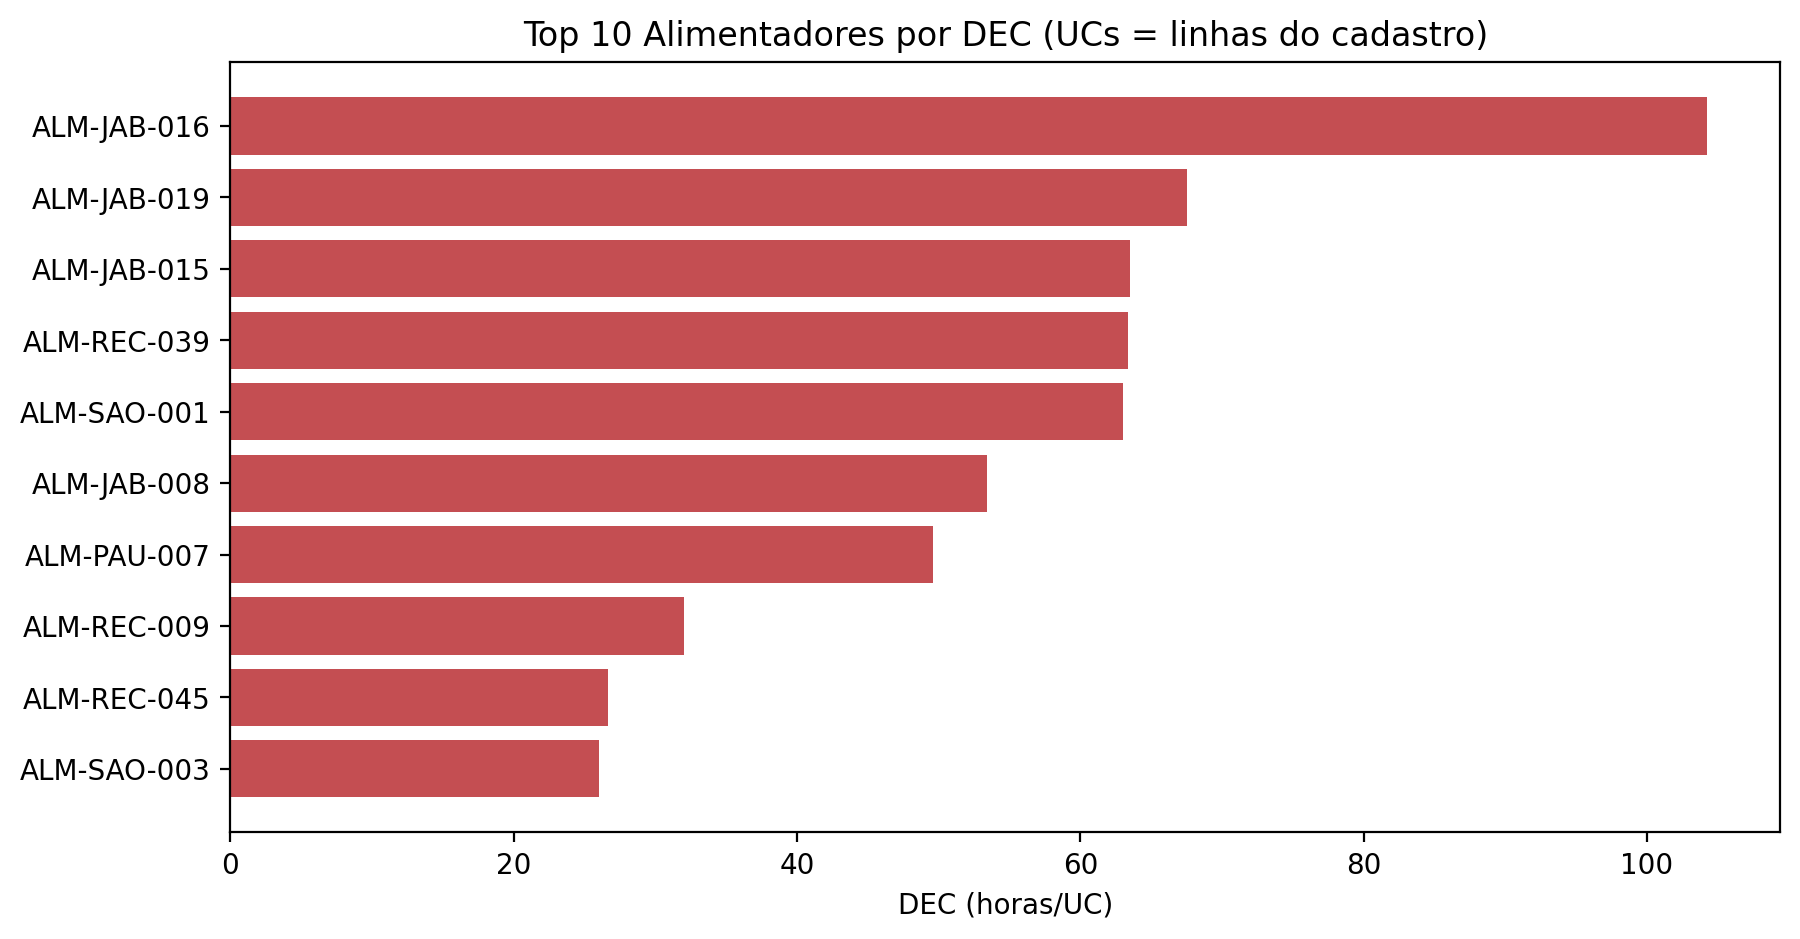

In [11]:
# Gráfico 1: top 10 DEC (linhas do cadastro)
fig, ax = plt.subplots(figsize=(10, 5))
top10_dec_linhas_sorted = top10_dec_linhas.sort_values("DEC_horas")
ax.barh(top10_dec_linhas_sorted["alimentador"], top10_dec_linhas_sorted["DEC_horas"], color="#c44e52")
ax.set_xlabel("DEC (horas/UC)")
ax.set_title("Top 10 Alimentadores por DEC (UCs = linhas do cadastro)")
exibir_grafico(fig, "01_top10_DEC_linhas")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\02_top10_DEC_distintos.png


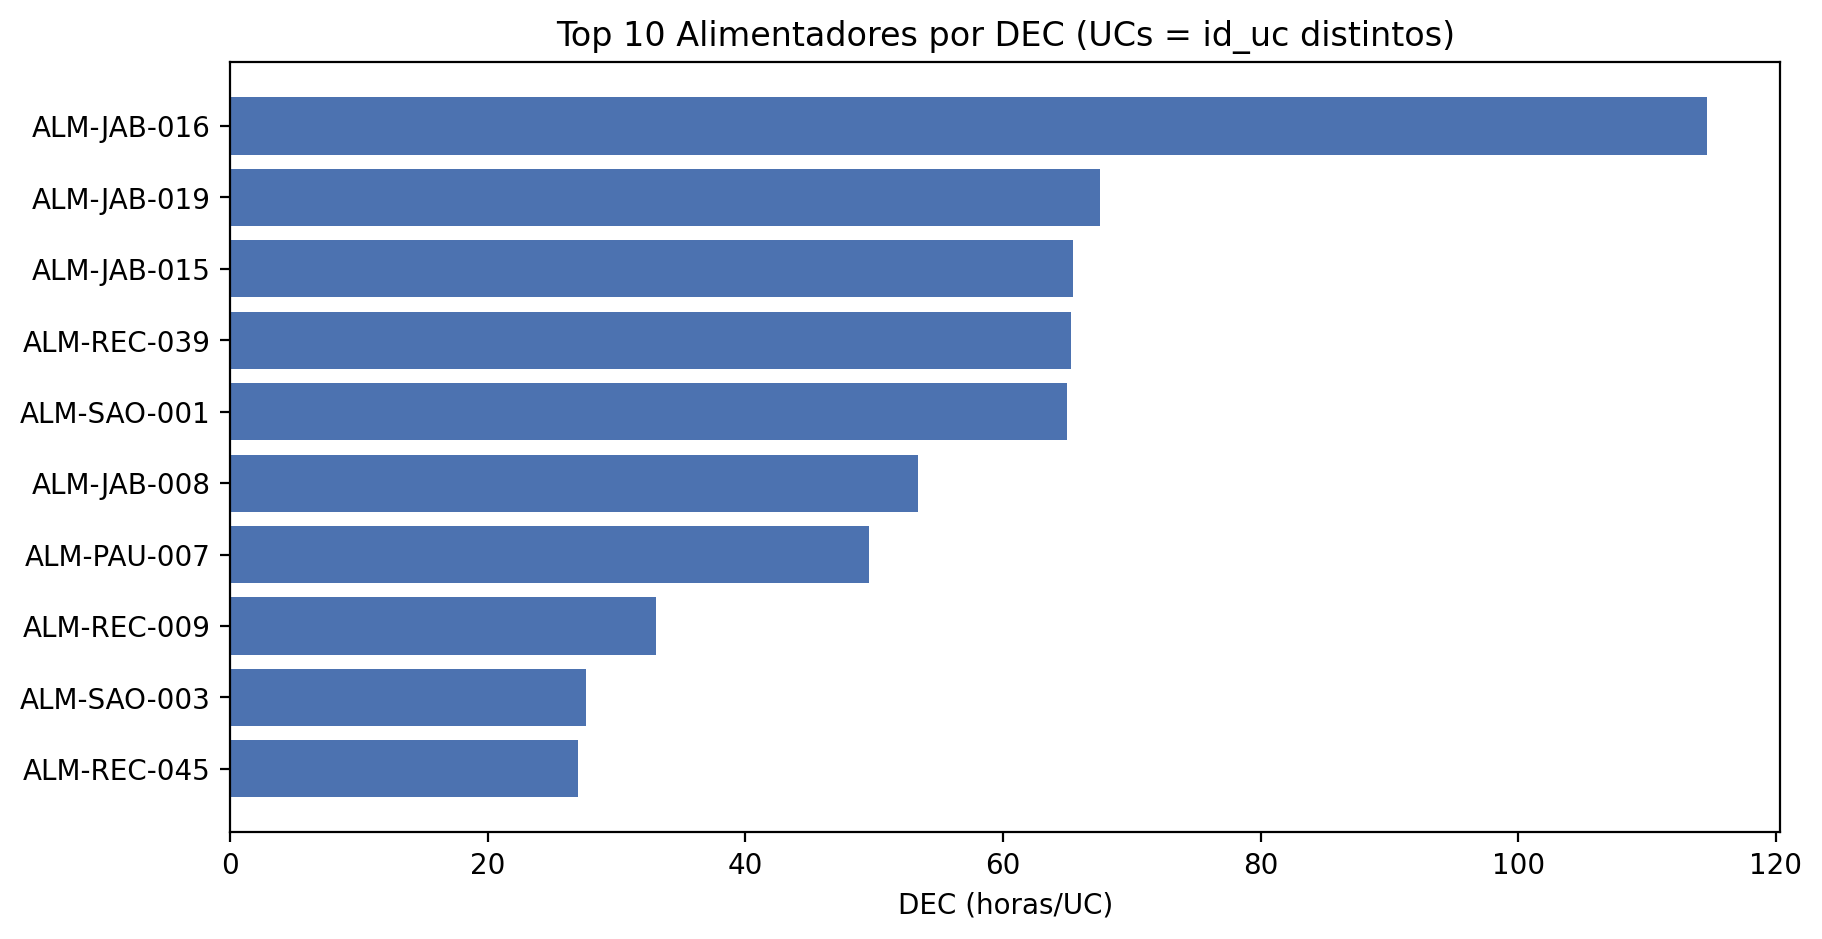

In [12]:
# Gráfico 2: top 10 DEC (UCs distintas)
fig, ax = plt.subplots(figsize=(10, 5))
top10_dec_dist_sorted = top10_dec_dist.sort_values("DEC_horas")
ax.barh(top10_dec_dist_sorted["alimentador"], top10_dec_dist_sorted["DEC_horas"], color="#4c72b0")
ax.set_xlabel("DEC (horas/UC)")
ax.set_title("Top 10 Alimentadores por DEC (UCs = id_uc distintos)")
exibir_grafico(fig, "02_top10_DEC_distintos")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\03_top10_FEC_linhas.png


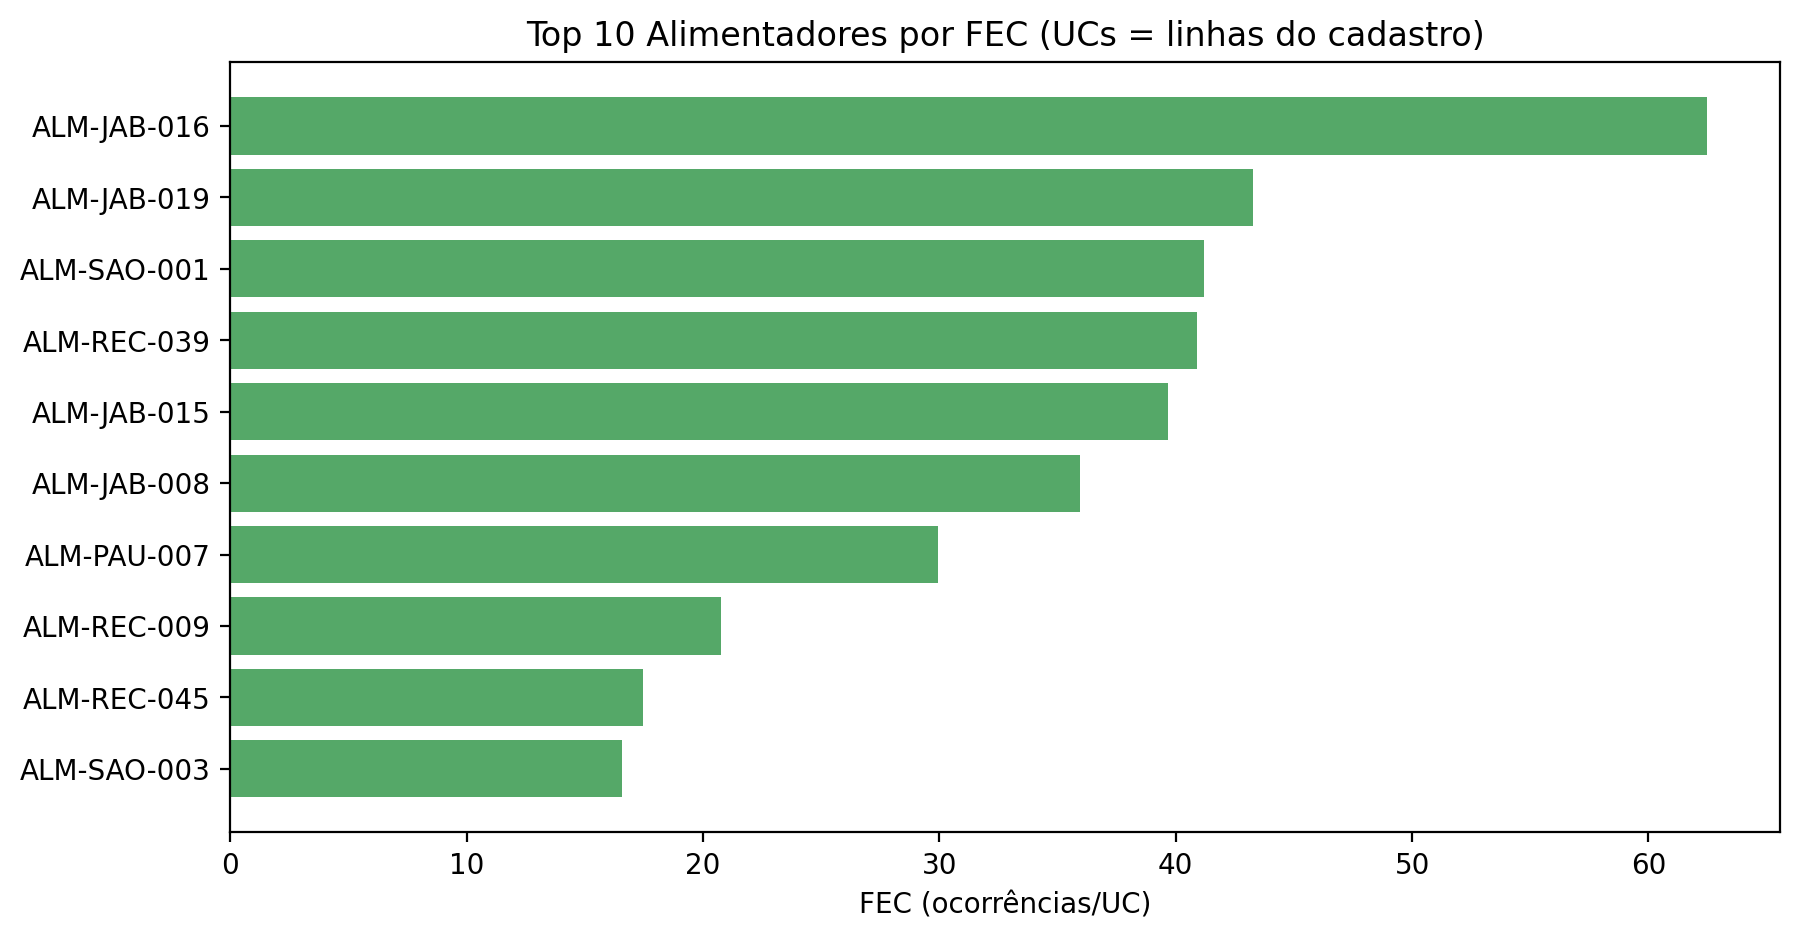

In [13]:
# Gráfico 3: top 10 FEC (linhas do cadastro)
fig, ax = plt.subplots(figsize=(10, 5))
top10_fec_linhas_sorted = top10_fec_linhas.sort_values("FEC")
ax.barh(top10_fec_linhas_sorted["alimentador"], top10_fec_linhas_sorted["FEC"], color="#55a868")
ax.set_xlabel("FEC (ocorrências/UC)")
ax.set_title("Top 10 Alimentadores por FEC (UCs = linhas do cadastro)")
exibir_grafico(fig, "03_top10_FEC_linhas")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\04_evolucao_mensal_ocorrencias.png


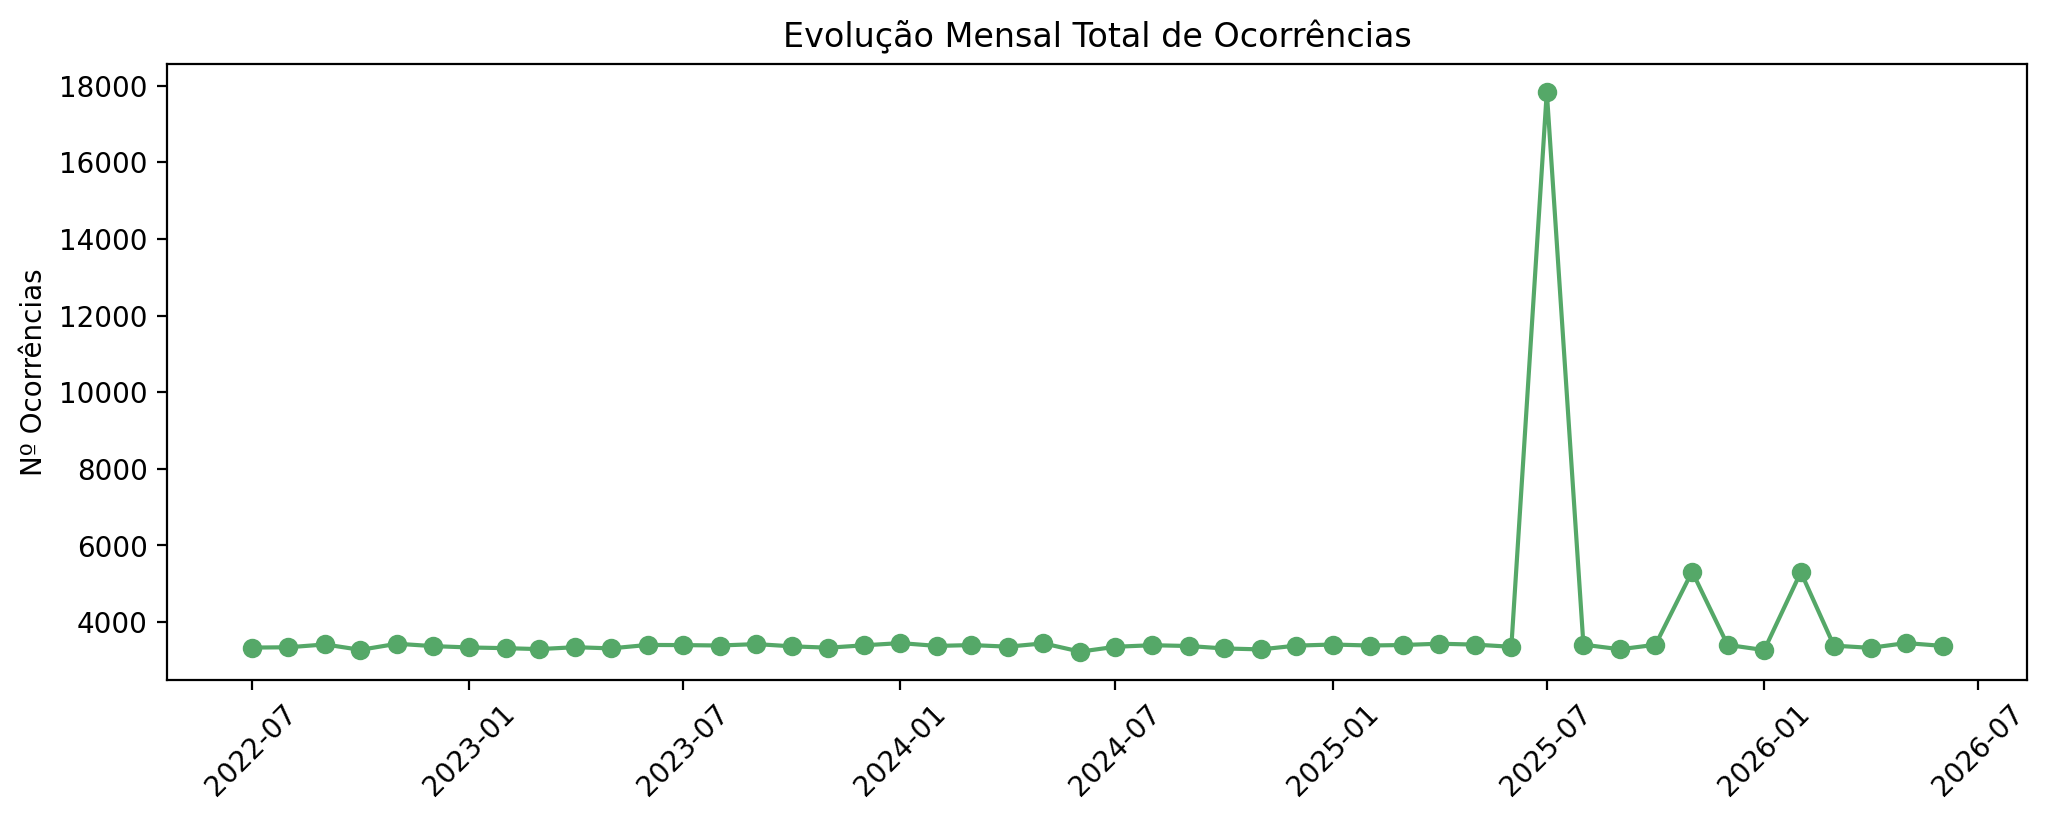

In [14]:
# Gráfico 4: evolução mensal ocorrências
fig, ax = plt.subplots(figsize=(12, 4))
evolucao.index = pd.to_datetime(evolucao.index)
ax.plot(evolucao.index, evolucao.values, marker="o", color="#55a868")
ax.set_ylabel("Nº Ocorrências")
ax.set_title("Evolução Mensal Total de Ocorrências")
ax.tick_params(axis='x', rotation=45)
exibir_grafico(fig, "04_evolucao_mensal_ocorrencias")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\05_dec_por_ano_top10.png


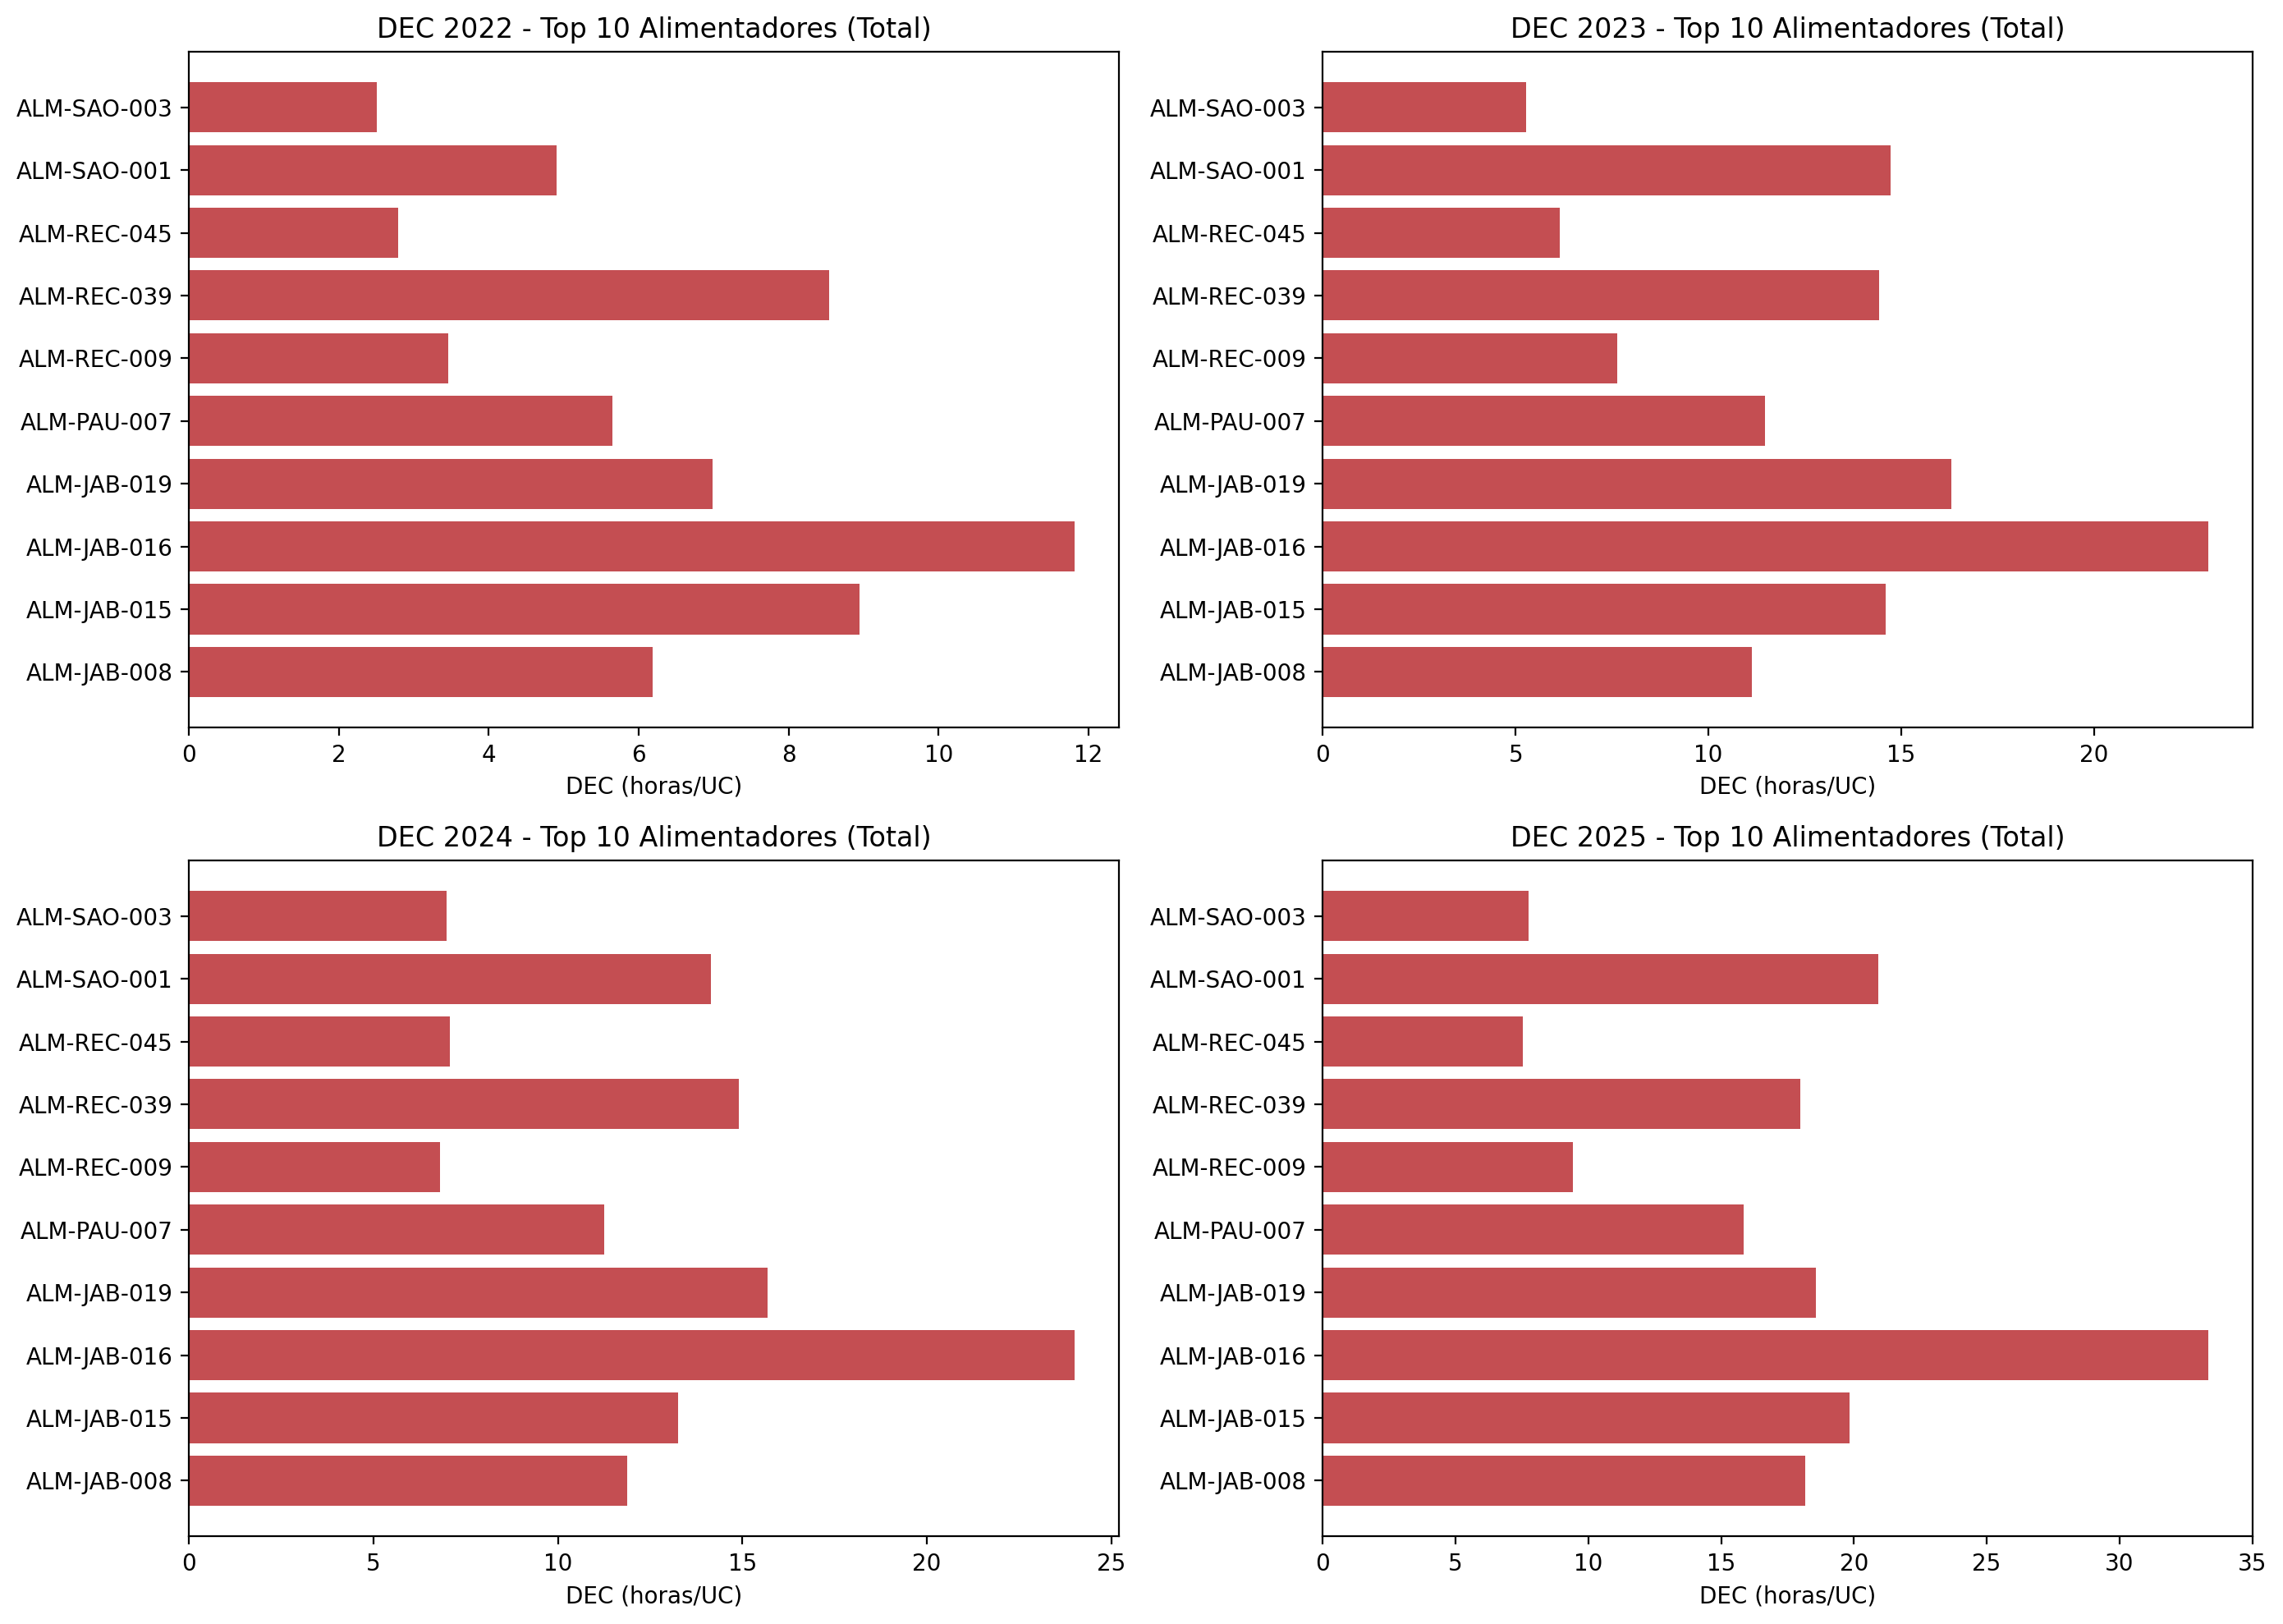

In [15]:
# Gráfico 5: DEC por ano (top 10 alimentadores do total)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for idx, ano in enumerate(anos[:4]):
    ax = axes[idx]
    df_linhas_ano = resultados_por_ano[str(ano)]["linhas_cadastro"]
    # Filtrar só os top 10 do total
    df_ano_top = {k: v for k, v in df_linhas_ano.items() if k in top10_alim_piores}
    if df_ano_top:
        alims = list(df_ano_top.keys())
        decs = [df_ano_top[a]["DEC_horas"] for a in alims]
        ax.barh(alims, decs, color="#c44e52")
    ax.set_xlabel("DEC (horas/UC)")
    ax.set_title(f"DEC {ano} - Top 10 Alimentadores (Total)")
fig.tight_layout()
exibir_grafico(fig, "05_dec_por_ano_top10")

In [16]:
# Helper para JSON seguro
def json_safe(obj):
    if isinstance(obj, dict):
        return {k: json_safe(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [json_safe(v) for v in obj]
    elif isinstance(obj, float):
        if pd.isna(obj) or np.isinf(obj):
            return None
        return obj
    elif pd.isna(obj):
        return None
    return obj

def fmt_valor(v):
    if v is None or pd.isna(v) or (isinstance(v, float) and np.isinf(v)):
        return "indefinido"
    return v

In [17]:
# Monta JSON de saída
resultado = {
    "suposicao": "Cada ocorrência afeta 1 UC (a UC informada na ocorrência).",
    "falhas_conversao": {
        "duracao_min": falhas_dur,
        "data_abertura": falhas_data,
    },
    "periodo_total": {
        "linhas_cadastro": {
            "por_alimentador": json_safe(df_linhas_total.set_index("alimentador")[["n_ucs", "n_ocorrencias", "soma_duracao_min", "FEC", "DEC_horas"]].to_dict(orient="index")),
            "top10_DEC": json_safe(top10_dec_linhas.set_index("alimentador")[["DEC_horas", "FEC", "n_ucs"]].to_dict(orient="index")),
            "top10_FEC": json_safe(top10_fec_linhas.set_index("alimentador")[["FEC", "DEC_horas", "n_ucs"]].to_dict(orient="index")),
        },
        "ucs_distintas": {
            "por_alimentador": json_safe(df_distintos_total.set_index("alimentador")[["n_ucs", "n_ocorrencias", "soma_duracao_min", "FEC", "DEC_horas"]].to_dict(orient="index")),
            "top10_DEC": json_safe(top10_dec_dist.set_index("alimentador")[["DEC_horas", "FEC", "n_ucs"]].to_dict(orient="index")),
        },
        "pct_horas_interrupcao_10pct_piores_DEC": fmt_valor(pct_horas_piores),
    },
    "por_ano": json_safe(resultados_por_ano),
    "evolucao_mensal_ocorrencias": json_safe(evolucao_dict),
    "piores_10_alimentadores_detalhes": json_safe(detalhes_piores),
    "alimentadores_sem_cadastro": {
        "quantidade": len(alim_sem_cadastro),
        "lista": sorted(list(alim_sem_cadastro)),
    },
    "alimentadores_sem_ucs_no_cadastro": {
        "quantidade": len(alim_sem_ucs),
        "lista": alim_sem_ucs,
    },
    "observacoes": [
        f"Falhas conversão duracao_min: {falhas_dur}",
        f"Falhas conversão data_abertura: {falhas_data} (formato detectado automaticamente)",
        "UCs por alimentador contadas de duas formas: linhas do cadastro e id_uc distintos.",
        "DEC = (soma duração min / 60) / UCs; FEC = n_ocorrencias / UCs.",
        "Limites ANEEL não estão nos dados; não foram aplicados.",
        f"Alimentadores em ocorrências sem cadastro: {len(alim_sem_cadastro)} (não têm FEC/DEC calculado).",
        f"Alimentadores sem UCs no cadastro: {len(alim_sem_ucs)} (ficaram sem FEC/DEC).",
        "Para os 10 piores por DEC: reportados município/bairro predominantes, tipo/causa dominantes e % do DEC por causa.",
    ],
}

resultado = json_safe(resultado)

with open(PASTA_RESULTADOS / "beatriz_dec_fec_por_alimentador_dados_brutos.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, ensure_ascii=False, indent=2, allow_nan=False)
print("JSON salvo.")

JSON salvo.
